In [5]:
from langchain_openrouter import ChatOpenRouter
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_classic.vectorstores import FAISS
from langchain.tools import tool
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, AIMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition
import os
load_dotenv()


True

In [61]:
api_key = os.getenv("OPENROUTER_API_KEY")
if not api_key:
    raise ValueError("OPENROUTER_API_KEY environment variable is not set.")

llm = ChatOpenRouter(
    model="dots-studio/dots-3-note-preview:free",
    api_key=api_key,
    temperature=0,
    max_tokens=1024
)

In [62]:
print(llm.invoke("Say hello").content)



Hello! 👋 I'm dots, an AI model developed by Dots Studio at rednote. How can I help you today?


In [11]:
loader = PyPDFLoader(file_path = "LLM.pdf")
documents = loader.load()

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/RYYBNH+NimbusRomNo9L-Regu', '/FontDescriptor': IndirectObject(129, 0, 2221646166160), '/Type': '/Font', '/FirstChar': 2, '/LastChar': 252, '/Widths': [556, 556, 0, 0, 611, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 333, 408, 500, 500, 833, 778, 333, 333, 333, 500, 564, 250, 333, 250, 278, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 278, 278, 0, 564, 0, 444, 0, 722, 667, 667, 722, 611, 556, 722, 722, 333, 389, 722, 611, 889, 722, 722, 556, 722, 667, 556, 611, 722, 722, 944, 722, 722, 611, 333, 0, 333, 0, 500, 333, 444, 500, 444, 500, 444, 333, 500, 500, 278, 278, 500, 278, 778, 500, 500, 500, 500, 333, 389, 278, 500, 500, 722, 500, 500, 444, 480, 0, 480, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 444, 444, 350, 500, 1000, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 760, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [12]:
for doc in documents:
    print(f"Document: {doc.page_content}, Metadata: {doc.metadata}")

Document: arXiv:2501.09223v1  [cs.CL]  16 Jan 2025
Foundations of
Large Language Models
Tong Xiao and Jingbo Zhu
January 17, 2025
NLP Lab, Northeastern University & NiuTrans Research, Metadata: {'producer': 'GPL Ghostscript 10.01.2', 'creator': 'LaTeX with hyperref', 'creationdate': '2025-01-16T20:13:48-05:00', 'moddate': '2025-01-16T20:13:48-05:00', 'title': '', 'subject': '', 'author': '', 'keywords': '', 'source': 'LLM.pdf', 'total_pages': 231, 'page': 0, 'page_label': '1'}
Document: Copyright © 2021-2025 Tong Xiao and Jingbo Zhu
NATURAL LANGUAGE PROCESSING LAB, N ORTHEASTERN UNIVERSITY
&
NIUTRANS RESEARCH
Licensed under the Creative Commons Attribution-NonComme rcial 4.0 Unported License (the
“License”). Y ou may not use this ﬁle except in compliance wit h the License. Y ou may ob-
tain a copy of the License at http://creativecommons.org/licenses/by-nc/4.0. Unless
required by applicable law or agreed to in writing, software distributed under the License is dis-
tributed on an “ AS 

In [18]:
splitter = RecursiveCharacterTextSplitter(chunk_size = 1000, chunk_overlap = 100)
chunks = splitter.split_documents(documents)


In [19]:
len(chunks)

779

In [26]:
from langchain_huggingface import HuggingFaceEmbeddings

embedding = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    encode_kwargs={"normalize_embeddings": True},
)
vector_store = FAISS.from_documents(chunks, embedding)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 823.97it/s]


In [27]:
retriever = vector_store.as_retriever(search_type = "similarity", search_kwargs = {"k": 3})

In [28]:
documents

[Document(metadata={'producer': 'GPL Ghostscript 10.01.2', 'creator': 'LaTeX with hyperref', 'creationdate': '2025-01-16T20:13:48-05:00', 'moddate': '2025-01-16T20:13:48-05:00', 'title': '', 'subject': '', 'author': '', 'keywords': '', 'source': 'LLM.pdf', 'total_pages': 231, 'page': 0, 'page_label': '1'}, page_content='arXiv:2501.09223v1  [cs.CL]  16 Jan 2025\nFoundations of\nLarge Language Models\nTong Xiao and Jingbo Zhu\nJanuary 17, 2025\nNLP Lab, Northeastern University & NiuTrans Research'),
 Document(metadata={'producer': 'GPL Ghostscript 10.01.2', 'creator': 'LaTeX with hyperref', 'creationdate': '2025-01-16T20:13:48-05:00', 'moddate': '2025-01-16T20:13:48-05:00', 'title': '', 'subject': '', 'author': '', 'keywords': '', 'source': 'LLM.pdf', 'total_pages': 231, 'page': 1, 'page_label': 'i'}, page_content='Copyright © 2021-2025 Tong Xiao and Jingbo Zhu\nNATURAL LANGUAGE PROCESSING LAB, N ORTHEASTERN UNIVERSITY\n&\nNIUTRANS RESEARCH\nLicensed under the Creative Commons Attributio

In [36]:
@tool
def rag_tool(query):
    """
    Retrieves the K most semantically related documents from the Knowledge base.
    """
    result = retriever.invoke(query)
    context = [doc.page_content for doc in result]
    metadata = [doc.metadata for doc in result]
    return {
        "query": query,
        "context": context,
        "metadata": metadata
    }

In [63]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [64]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [65]:
# Define the node
def chat_node(state: ChatState) -> ChatState:
    message = state["messages"]
    result = llm_with_tools.invoke(message)
    return {"messages": [result]}

In [66]:
tool_node = ToolNode(tools)

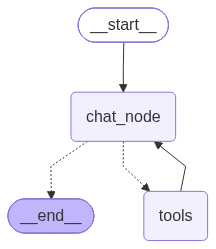

In [67]:
graph = StateGraph(ChatState)

graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)

graph.add_edge(START, "chat_node")
graph.add_conditional_edges("chat_node", tools_condition)
graph.add_edge("tools", "chat_node")

chatbot = graph.compile()
chatbot

In [68]:
result = chatbot.invoke(
    {
        "messages": [
            HumanMessage(content = "Using the pdf notes answer what is LLM?")
        ]
    }
)

In [72]:
result

{'messages': [HumanMessage(content='Using the pdf notes answer what is LLM?', additional_kwargs={}, response_metadata={}, id='9c1cea3c-b735-4095-96fc-bebe5eb604a7'),
  AIMessage(content='\n\n\n', additional_kwargs={'reasoning_content': 'The user is asking "what is LLM?" based on PDF notes. I should use the rag_tool to retrieve relevant documents from the Knowledge base. Let me search for information about LLM.\n', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'The user is asking "what is LLM?" based on PDF notes. I should use the rag_tool to retrieve relevant documents from the Knowledge base. Let me search for information about LLM.\n'}]}, response_metadata={'model_name': 'dots-studio/dots-3-note-preview:free', 'id': 'gen-1792160881-i54xTUUAPhDXU59yL8Nn', 'created': 1792160881, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_comple

In [ ]:
# Final Result
result["messages"][-1].content

'\n\nBased on the PDF notes, here\'s what LLM (Large Language Model) is:\n\n## Definition\nLLMs are **generative models** like GPT, though the term can broadly cover other types of models like BERT. They are a type of foundation model designed for language tasks.\n\n## Key Characteristics\n\n1. **Architecture**: Many LLMs share a similar architecture based on the Transformer model. They follow an **autoregressive process** - each time the model takes a token as input and predicts the next token that maximizes the probability.\n\n2. **Size**: These models are called "large" because both their **depth and width are significant**, meaning they have many layers and parameters.\n\n3. **Training**: LLMs are trained using **maximum likelihood** on large datasets of sequences. The training objective is to maximize the log-likelihood of sequences in the training data.\n\n4. **Functionality**: They are designed for **language modeling tasks** and can be improved to handle very long texts through